In [37]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
speed_of_light = 3e8 
radius_earth = 6371e3
keplers_constant = 3.986e14

In [23]:
def calculate_path_loss(f_hertz, d_meters):
    return -20 * math.log10((4*math.pi * d_meters * f_hertz) / speed_of_light)

In [24]:
path_loss_nadir = calculate_path_loss(30e9, 600e3)
path_loss_10deg = calculate_path_loss(30e9, 1942e3)

print(f"Path loss at 10 degrees elevation angle over 600 km altitude: {path_loss_10deg} dB")
print(f"Path loss at 30 GHz over 600 km: {path_loss_nadir} dB")

Path loss at 10 degrees elevation angle over 600 km altitude: -187.74918179188165 dB
Path loss at 30 GHz over 600 km: -177.54722228811482 dB


In [25]:
def calculate_atmospheric_loss(elevation_angle, height, attenuation_per_km):
    d = height / math.sin(math.radians(elevation_angle))
    return attenuation_per_km * d  

In [26]:
troposphere_thickness = 20 # km
atmospheric_attenuation_per_km = -0.25  # dB/km

atm_attenuation_nadir = calculate_atmospheric_loss(90, troposphere_thickness, atmospheric_attenuation_per_km)
atm_attenuation_10deg = calculate_atmospheric_loss(10, troposphere_thickness, atmospheric_attenuation_per_km)

print(f"Atmospheric loss through troposphere, nadir angle: {atm_attenuation_nadir} dB")
print(f"Atmospheric loss through troposphere, 10 degree elevation angle: {atm_attenuation_10deg} dB")

Atmospheric loss through troposphere, nadir angle: -5.0 dB
Atmospheric loss through troposphere, 10 degree elevation angle: -28.79385241571817 dB


In [27]:
TxPower = 10
TxGain = 4
RcvGain = 6

rx_power_nadir = TxPower + TxGain + RcvGain + path_loss_nadir + atm_attenuation_nadir
rx_power_10deg = TxPower + TxGain + RcvGain + path_loss_10deg + atm_attenuation_10deg

print(f"Received power at nadir angle: {rx_power_nadir} dBW")
print(f"Received power at 10 degree elevation angle: {rx_power_10deg} dBW")

Received power at nadir angle: -162.54722228811482 dBW
Received power at 10 degree elevation angle: -196.54303420759982 dBW


In [65]:
def satellite_v(altitude_m):
   return np.sqrt(keplers_constant / ((radius_earth + altitude_m))) # sqrt( m^3/s^2 / m ) = sqrt( m^2/s^2 ) = m/s

def doppler_f_hz(altitude_m, f_hz, elevation_angle_deg=20.07):
    v = satellite_v(altitude_m) # m/s
    elevation_angle_rad = np.radians(elevation_angle_deg)
    return (v*radius_earth*f_hz*np.cos(elevation_angle_rad)) / (speed_of_light*(radius_earth + altitude_m))  # (m/s * m * s^-1) / (m/s * m)) = (m^2/s^2) / (m^2/s) = 1/s = Hz

In [75]:
doppler_shift_nadir = doppler_f_hz(600e3, 30e9, 90)
doppler_shift_10deg = doppler_f_hz(600e3, 30e9, 10)

print(f"Doppler shift at nadir angle: {doppler_shift_nadir} Hz")
print(f"Doppler shift at 10 degree elevation angle: {doppler_shift_10deg} Hz or {doppler_shift_10deg/1e3} KHz")

Doppler shift at nadir angle: 4.2316962267159505e-11 Hz
Doppler shift at 10 degree elevation angle: 680589.2532220533 Hz or 680.5892532220533 KHz


In [73]:
def q(x):
    return 0.5 * math.erfc(x / math.sqrt(2))

def calculate_ber_bpsk(cnr_db):
    cnr_linear = 10 ** (cnr_db / 10)
    return q(math.sqrt(cnr_linear))

def calculate_ber_qpsk(cnr_db):
    cnr_linear = 10 ** (cnr_db / 10)
    return q(math.sqrt(cnr_linear*2))

cnr_range = np.linspace(5 ,15, 10)
ber_bpsk = [calculate_ber_bpsk(cnr) for cnr in cnr_range]
ber_qpsk = [calculate_ber_qpsk(cnr) for cnr in cnr_range]

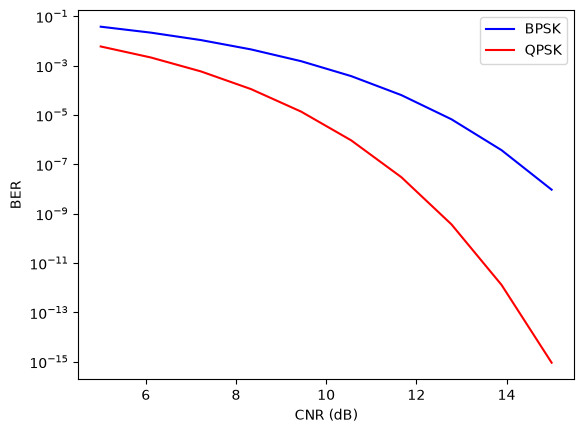

In [54]:
plt.plot(cnr_range, ber_bpsk, label='BPSK', color='blue')
plt.plot(cnr_range, ber_qpsk, label='QPSK', color='red')
plt.xlabel('CNR (dB)')
plt.ylabel('BER')
plt.yscale('log')
plt.legend()
plt.show()

In [58]:
if_f_mhz = 70
if_f_ghz = if_f_mhz / 1e3
rf_f_ghz = 4.864
f1 = rf_f_ghz - if_f_ghz
f2 = rf_f_ghz + if_f_ghz
print(f"Mixer frequencies needed: {f1} GHz and {f2} GHz")

Mixer frequencies needed: 4.794 GHz and 4.934 GHz


In [56]:
def calculate_noise_temperature(t_in, t_rf, t_m, t_if, g_lna, g_m):
   
    g_lna_linear = 10 ** (g_lna / 10)
    g_m_linear = 10 ** (g_m / 10) 
    
    return t_in + t_rf + (t_m / g_lna_linear) + (t_if / (g_lna_linear * g_m_linear))

calculated_noise_temp = calculate_noise_temperature(25, 15, 30, 150, 30, -3)
print(f"Calculated system noise temperature: {calculated_noise_temp} K")

Calculated system noise temperature: 40.329289347245336 K


In [59]:
def calculate_antenna_gain_db(diameter_m, efficiency, frequency_hz):
    wavelength = speed_of_light / frequency_hz
    gain_linear = efficiency * (math.pi * diameter_m / wavelength) ** 2
    return 10 * math.log10(gain_linear)

def estimate_beamwidth(diameter_m, frequency_hz):
    wavelength = speed_of_light / frequency_hz
    return 75 * (wavelength / diameter_m)  # in degrees

def calculate_gain_to_temperature_ratio(antenna_gain_db, system_noise_temp_k):
    t_dBK = 10 * math.log10(system_noise_temp_k)
    return antenna_gain_db - t_dBK

antenna_gain = calculate_antenna_gain_db(1.2, 0.65, 4.2e9)
beamwidth = estimate_beamwidth(1.2, 4.2e9)
gain_to_temp_ratio = calculate_gain_to_temperature_ratio(antenna_gain, 75)
print(f"Antenna gain: {antenna_gain} dB")
print(f"Estimated beamwidth: {beamwidth} degrees")
print(f"Gain-to-temperature ratio: {gain_to_temp_ratio} dB/K")


Antenna gain: 32.578316654828484 dB
Estimated beamwidth: 4.464285714285714 degrees
Gain-to-temperature ratio: 13.827704020911483 dB/K


In [62]:
def calculate_power_available(power_density, area, efficiency):
    return power_density * area * efficiency

power_available = calculate_power_available(1.39, 10, 0.25)
print(f"Available power: {power_available} kW")
print(f"Available power for transponders: {power_available - 2} kW")

Available power: 3.4749999999999996 kW
Available power for transponders: 1.4749999999999996 kW
